# Courbes d'entraînement et inspection des prédictions

Ce notebook lit `history.jsonl`, `metrics.json` et `predictions.jsonl` produits par le pipeline. Il compare la validation au test officiel et affiche quelques erreurs représentatives.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz.distance import Levenshtein
from PIL import Image

def locate_run():
    candidates = [Path.cwd(), *Path.cwd().parents]
    for root in candidates:
        run = root / 'runs' / 'baseline'
        if (run / 'history.jsonl').is_file(): return run
        run = root / 'outputs' / 'arabic_ocr' / 'runs' / 'baseline'
        if (run / 'history.jsonl').is_file(): return run
    raise FileNotFoundError('Run baseline introuvable.')

RUN = locate_run()
PROJECT = RUN.parents[2] if RUN.parent.name == 'arabic_ocr' else RUN.parents[3]
print('Run :', RUN)

Run : C:\Users\sail_\Documents\Codex\2026-10-29\oui-il-existe-des-datasets-adapt\outputs\arabic_ocr\runs\baseline


In [2]:
history = [json.loads(line) for line in (RUN / 'history.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
epochs = pd.DataFrame([row for row in history if row.get('epoch', 0) > 0])
val = pd.json_normalize(epochs['validation'])
curves = pd.concat([epochs[['epoch','train_ctc_loss']].reset_index(drop=True), val.add_prefix('val_')], axis=1)
curves[['epoch','train_ctc_loss','val_cer','val_wer','val_exact_accuracy']]

,epoch,train_ctc_loss,val_cer,val_wer,val_exact_accuracy
0,1,2.950613,0.426474,0.952748,0.000000
1,2,0.377465,0.043867,0.180788,0.268103
2,3,0.167859,0.023239,0.087098,0.524138
3,4,0.139013,0.021384,0.081025,0.521552
4,5,0.123360,0.022141,0.087691,0.530172
5,6,0.105878,0.019846,0.074063,0.559483
6,7,0.107038,0.016453,0.057695,0.658621
7,8,0.091961,0.014000,0.048363,0.686207


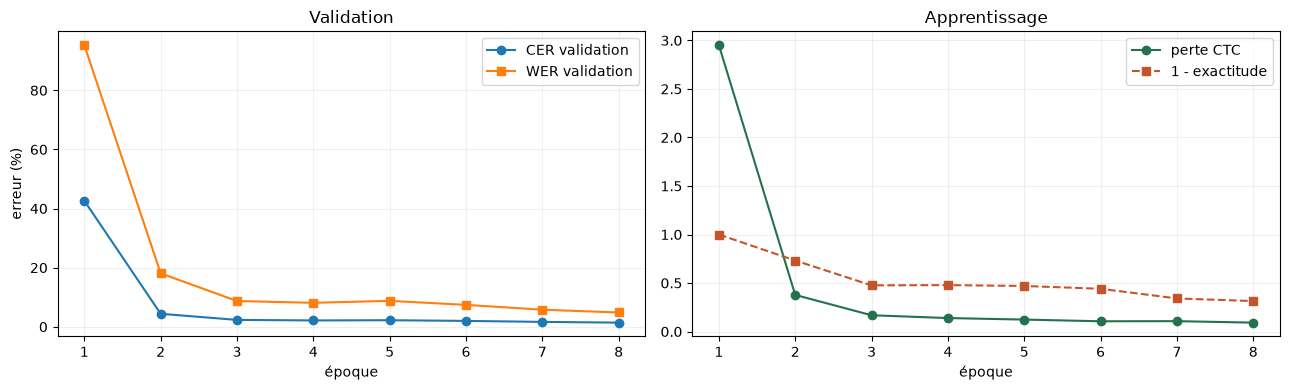

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(curves['epoch'], 100*curves['val_cer'], 'o-', label='CER validation')
axes[0].plot(curves['epoch'], 100*curves['val_wer'], 's-', label='WER validation')
axes[0].set(xlabel='époque', ylabel='erreur (%)', title='Validation')
axes[0].legend()
axes[1].plot(curves['epoch'], curves['train_ctc_loss'], 'o-', color='#23724c', label='perte CTC')
axes[1].plot(curves['epoch'], 1-curves['val_exact_accuracy'], 's--', color='#c4552b', label='1 - exactitude')
axes[1].set(xlabel='époque', title='Apprentissage')
axes[1].legend()
for axis in axes: axis.grid(alpha=.2)
plt.tight_layout()
plt.show()

In [4]:
metrics_path = RUN / 'test' / 'metrics.json'
pred_path = RUN / 'test' / 'predictions.jsonl'
metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
predictions = pd.DataFrame([json.loads(line) for line in pred_path.read_text(encoding='utf-8').splitlines() if line.strip()])
print({key: metrics[key] for key in ('samples','cer','wer','exact_accuracy','seconds','lines_per_second')})
predictions['line_cer'] = predictions.apply(lambda row: Levenshtein.distance(row['reference'], row['prediction']) / max(1, len(row['reference'])), axis=1)
predictions.sort_values('line_cer', ascending=False).head(10)[['id','line_cer','reference','prediction']]

{'samples': 1212, 'cer': 0.014861294583883751, 'wer': 0.06935617573915447, 'exact_accuracy': 0.5165016501650165, 'seconds': 3.181916999999885, 'lines_per_second': 380.9024559723097}


,id,line_cer,reference,prediction
5,1 (145)__page_012__region_001.png,0.678571,الفرع الرابع الهيئة الخاصة بالتنمية الثقافية و...,ية المم، الية الرإثي ي الون
241,1 (118)__page_002__region_004_line_0002.png,0.409091,و 2018/12/28 فإنه قرر:,و11006 116 فإنه قرر:
100,1 (139)__page_007__region_001_line_0018.png,0.263158,المادة الرابعة عشرة,اللادة الرإبععرة
239,1 (139)__page_001__region_003_line_0003.png,0.260870,مديرية الشؤون القانونية,ميري الؤو القاوبية
26,1 (145)__page_005__region_001.png,0.250000,مشروع قانون تنظيمي رقم 04.16,مشوع قانون تنظمي رم 640
221,1 (118)__page_002__region_007_line_0005.png,0.227273,1426 (15 فبراير 2005).,2006 (12 فبراير 200).
103,1 (163)__page_001__region_015.png,0.208333,القيادات من 694 إلى 708.,القيادات من 146 إلى 100.
417,1 (163)__page_002__region_012_line_0003.png,0.196078,2.16.458 الصادر في 17 من شوال 1437 (22 يوليو 2...,104.147 الصادر في 17 من شوال 1443 (22 يوليو 20...
186,1 (11)__page_001__region_004_line_0001.png,0.173913,مديرية الشؤون القانونية,هطيرية الطؤو القانونية
1002,1 (118)__page_002__region_007_line_0004.png,0.166667,الثاني 1405 (21 يناير 1985) والمرسوم رقم 2-04-...,الثاني 1006 (12 يناير 1886) والمرسوم رقم 2-25-...


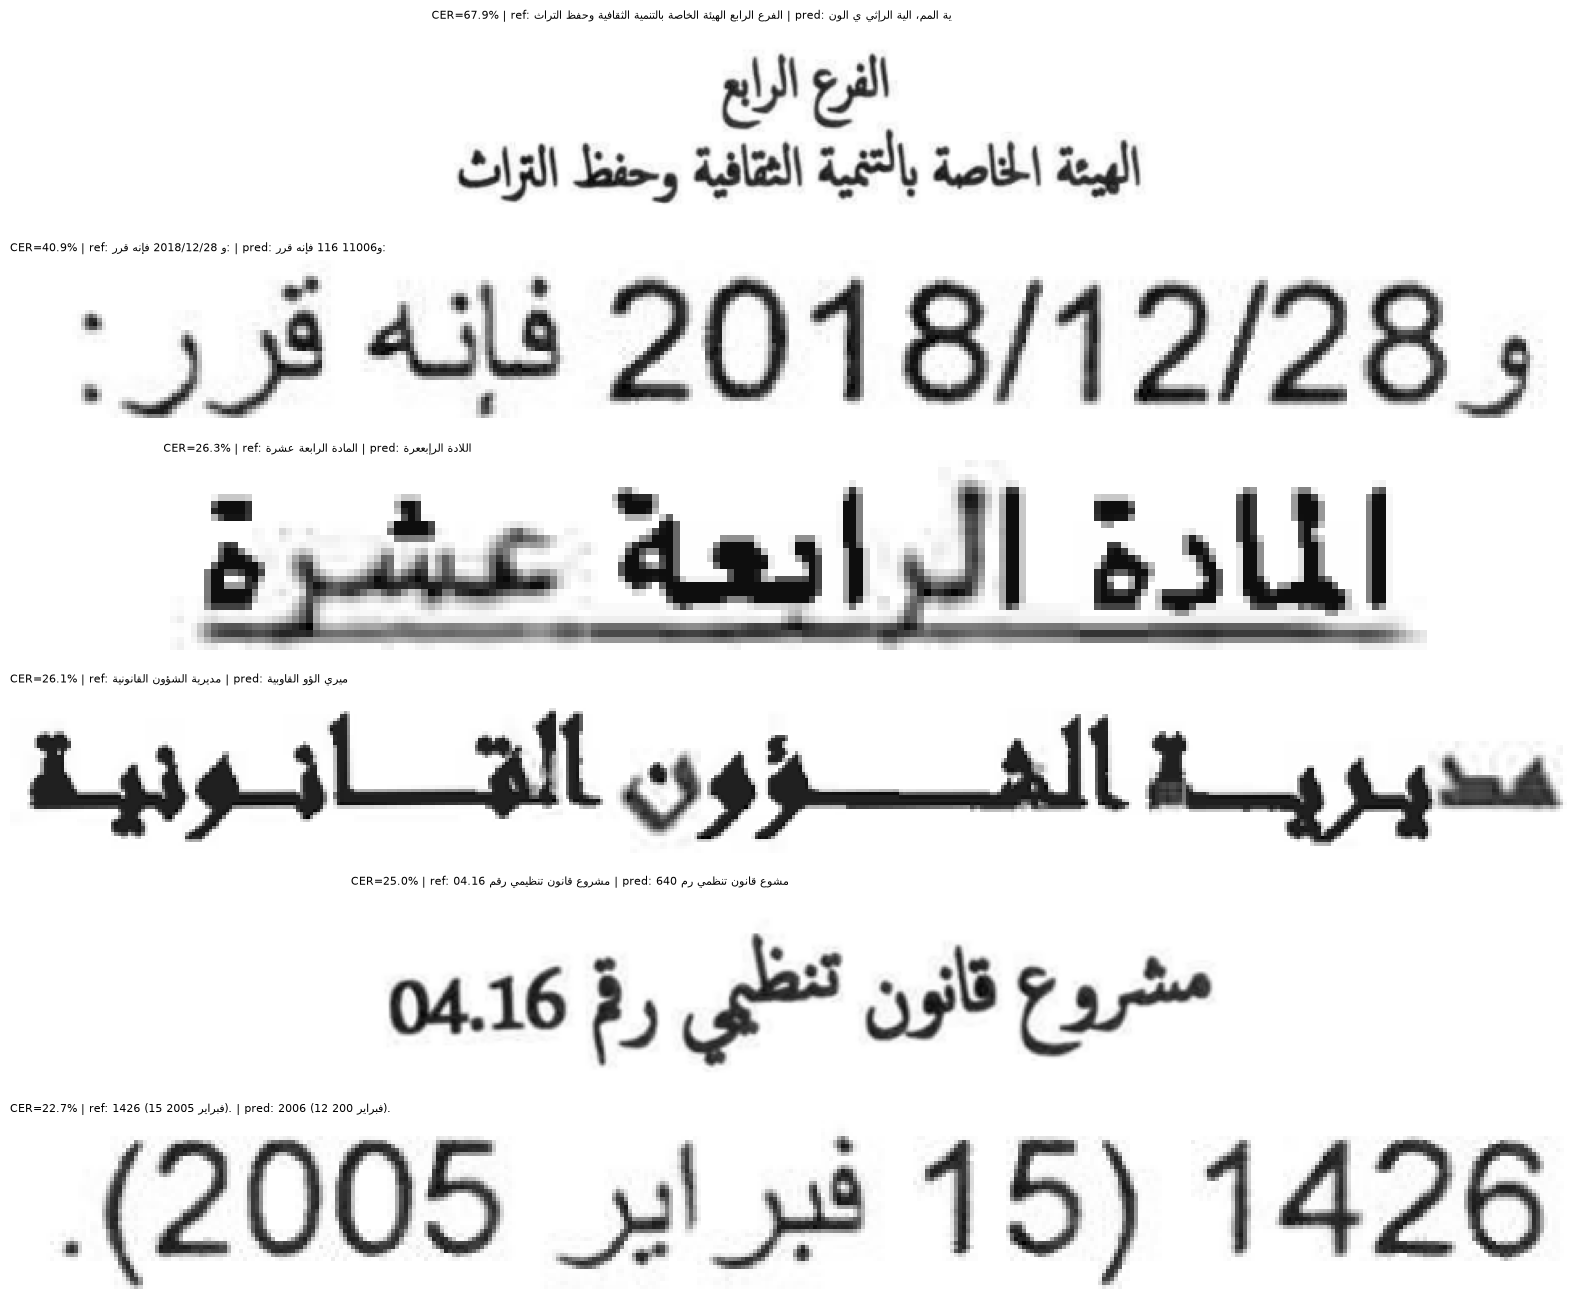

In [5]:
data_dir = PROJECT / 'work' / 'data' / 'gazette'
images = {json.loads(line)['id']: json.loads(line)['image'] for line in (data_dir/'test.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()}
worst = predictions.sort_values('line_cer', ascending=False).head(6)
fig, axes = plt.subplots(len(worst), 1, figsize=(16, max(4, 2.2*len(worst))))
axes = [axes] if len(worst) == 1 else axes
for axis, (_, row) in zip(axes, worst.iterrows()):
    with Image.open(images[row['id']]) as image: axis.imshow(image.convert('L'), cmap='gray')
    axis.set_title(f"CER={row['line_cer']:.1%} | ref: {row['reference'][:140]} | pred: {row['prediction'][:140]}", loc='left', fontsize=8)
    axis.axis('off')
plt.tight_layout()
plt.show()